<a href="https://colab.research.google.com/github/Abhi712-ui/lis501-ipynb-files/blob/main/Week_5_Text_Similarity_and_Classification_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LIS 501 · Week 5
## Text similarity and text classification

**Our question:** Can the words in a post help us find related posts and predict which discussion group it belongs to?

We will use four categories from **20 Newsgroups**, a collection of Usenet discussion posts with group labels. We will inspect the texts, turn them into counts and TF-IDF weights, search for related posts, and evaluate a classifier on held-out posts.

By the end, you should be able to explain what a similarity score measures, distinguish retrieval from classification, and use a confusion matrix and a real error to assess a model.

| Part | Main activity |
|---|---|
| 1. Meet the dataset | Inspect labels, text quality, and length |
| 2. Counts and TF-IDF | Read a document–term representation |
| 3. Text similarity | Search with cosine, compare Jaccard, complete Exercise 1 |
| 4. Text classification | Train, evaluate, and complete Exercise 2 |
| 5. New text and wrap-up | Examine predictions and their limits |


# Setup · complete before class

Open this `.ipynb` in Google Colab and connect to a standard Python runtime. A CPU runtime is sufficient. Colab normally includes the libraries below; this notebook needs no language-model download.

The dataset loader downloads and caches the data on its first call. Run all Setup cells while connected to the internet. A new Colab runtime may need to download the data again. If downloading fails, check the connection and rerun the loader cell before proceeding. [1]

**Four-category teaching subset**

| Dataset label | Discussion area |
|---|---|
| `comp.graphics` | Computer graphics |
| `rec.sport.baseball` | Baseball |
| `rec.sport.hockey` | Hockey |
| `sci.space` | Space and spaceflight |

Baseball and hockey give us a related pair whose vocabulary may overlap. The full dataset has 20 categories. For an after-class extension, set `RUN_ALL_20_CATEGORIES = True` and run the whole notebook again; the code sets `CATEGORIES = None` to request every category.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.6.1


In [ ]:
RANDOM_STATE = 42
RUN_ALL_20_CATEGORIES = False

CATEGORIES = [
    'comp.graphics',
    'rec.sport.baseball',
    'rec.sport.hockey',
    'sci.space',
]
if RUN_ALL_20_CATEGORIES:
    CATEGORIES = None

## Load two separate partitions

The dataset supplies a **training partition** and a **test partition**, separated by posting date. We preserve that split. Training texts will supply the vocabulary, IDF weights, retrieval collection, and classifier. Test texts are reserved for evaluating predictions. [1, 9]

`remove=('headers', 'footers', 'quotes')` reduces shortcuts such as group names in headers and repeated quoted material. These filters use rules, so some signatures or quoted content may remain. The `text` column will keep the returned post body available for inspection. [1]

In [ ]:
train_data = fetch_20newsgroups(
    subset='train', categories=CATEGORIES,
    remove=('headers', 'footers', 'quotes'),
    shuffle=True, random_state=RANDOM_STATE,
)
test_data = fetch_20newsgroups(
    subset='test', categories=CATEGORIES,
    remove=('headers', 'footers', 'quotes'),
    shuffle=True, random_state=RANDOM_STATE,
)

class_names = np.array(train_data.target_names)
print('Training posts loaded:', len(train_data.data))
print('Test posts loaded:', len(test_data.data))
print('Selected categories:', len(class_names))

Training posts loaded: 2374
Test posts loaded: 1579
Selected categories: 4


## Put the posts in tables and check empty text

A **DataFrame** is a table: one row per post, one column per variable. The supplied helper gives each post a category name and removes missing or whitespace-only bodies. The summary reports exactly how many rows are excluded in each split.

Some nonempty posts may later have **no retained vocabulary terms**. We will count those rows separately and keep them in evaluation.

In [ ]:
def prepare_table(dataset, split_name):
    frame = pd.DataFrame({'text': dataset.data, 'target': dataset.target})
    frame['category'] = np.array(dataset.target_names)[dataset.target]
    frame['source_row'] = np.arange(len(frame))

    missing = frame['text'].isna()
    blank = frame['text'].fillna('').str.strip().eq('') & ~missing
    keep = ~(missing | blank)
    summary = {
        'split': split_name, 'loaded': len(frame),
        'missing': int(missing.sum()), 'blank': int(blank.sum()),
        'retained': int(keep.sum()),
    }
    return frame.loc[keep].reset_index(drop=True), summary

train_df, train_quality = prepare_table(train_data, 'train')
test_df, test_quality = prepare_table(test_data, 'test')
quality_summary = pd.DataFrame([train_quality, test_quality])
display(quality_summary)
print('Ready for the class demo.')

,split,loaded,missing,blank,retained
0,train,2374,0,66,2308
1,test,1579,0,44,1535


Ready for the class demo.


# 1. Meet the dataset

**Start with the unit of analysis.** One row is one post. Its `target` is a numeric code; `category` gives the readable group name. A label records the forum in which a post appeared. Individual posts can discuss several subjects or rely on context from a longer conversation.

Our exploratory summaries use **training texts**. The test texts will enter the workflow at evaluation.

In [ ]:
train_df['word_count'] = train_df['text'].str.split().str.len()

display(pd.DataFrame({'target': np.arange(len(class_names)), 'category': class_names}))
display(train_df[['category', 'word_count']].head())
display(train_df['word_count'].describe().round(1))

,target,category
0,0,comp.graphics
1,1,rec.sport.baseball
2,2,rec.sport.hockey
3,3,sci.space


,category,word_count
0,sci.space,4125
1,sci.space,28
2,rec.sport.baseball,37
3,sci.space,92
4,rec.sport.baseball,109


,word_count
count,2308.0
mean,175.7
std,522.4
min,1.0
25%,38.0
50%,73.0
75%,147.0
max,11251.0


`word_count` counts whitespace-separated pieces for a quick length summary. The vectorizer will apply its own token rules later.

**Discuss:** Are the categories balanced? Is a typical post short enough that one or two words could strongly affect its representation?

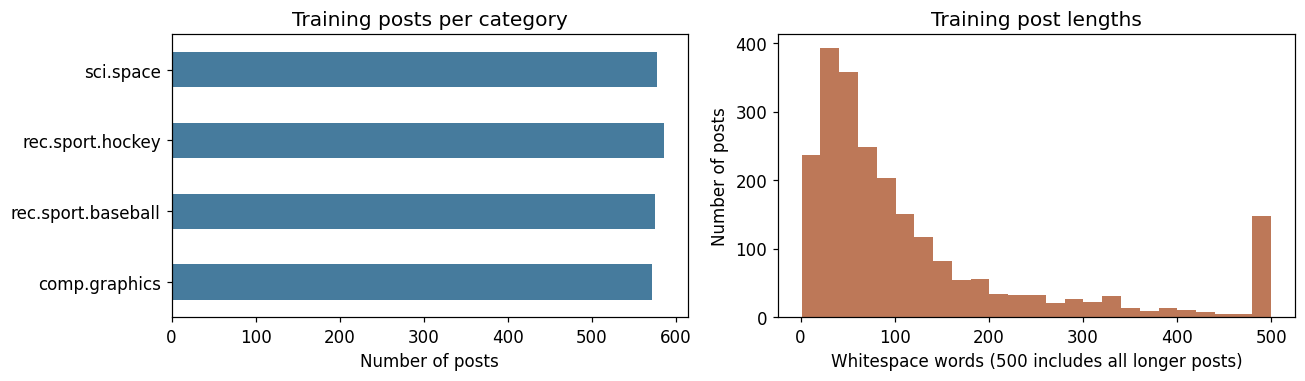

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, max(3.6, 0.25 * len(class_names))))

train_df['category'].value_counts().sort_index().plot.barh(
    ax=axes[0], color='#467B9D', title='Training posts per category'
)
axes[0].set_xlabel('Number of posts')
axes[0].set_ylabel('')

# Pool lengths of 500 words or more at 500 to keep the plot readable.
axes[1].hist(train_df['word_count'].clip(upper=500), bins=25, color='#BD7858')
axes[1].set_title('Training post lengths')
axes[1].set_xlabel('Whitespace words (500 includes all longer posts)')
axes[1].set_ylabel('Number of posts')
plt.tight_layout()
plt.show()

In [ ]:
# Choose a short space post that we can read and revisit.
candidates = train_df.index[
    train_df['category'].eq('sci.space') & train_df['word_count'].between(35, 90)
]
example_id = int(candidates[0])
print('Training row:', example_id)
print('Observed category:', train_df.loc[example_id, 'category'])
print(train_df.loc[example_id, 'text'])

Training row: 8
Observed category: sci.space
Hello everyone,

	I was hoping someone could help me out.  I'm writing a program
	for my astronautics class for assent of the shuttle into a low
	orbit.  There are two things I'd like to know, First, how much 
	time elapses between launch and the pitch over. Second, what is
	the cross-sectional area of the shuttle, srb's, and ext. tank.

	Thanks for any information, post or e-mail.


# 2. Counts and TF-IDF

**Bag-of-Words:** one row per document, one column per vocabulary term, and a count in each cell.

Our representation makes four explicit choices:

- Lowercase text and use scikit-learn's default tokens: sequences of at least two word characters. Digits can be part of a token.
- Remove the built-in English stopword list.
- Retain terms appearing in at least two training documents (`min_df=2`).
- Keep at most 10,000 terms, ranked by training-corpus frequency (`max_features=10000`). [2]

These are demonstration settings. Stopword removal and vocabulary limits can discard useful information; their suitability depends on the research question.

In [ ]:
count_vectorizer = CountVectorizer(
    lowercase=True, stop_words='english', min_df=2, max_features=10000
)

X_train_counts = count_vectorizer.fit_transform(train_df['text'])
terms = count_vectorizer.get_feature_names_out()

print('Count matrix shape (documents, vocabulary terms):', X_train_counts.shape)
print('First 15 vocabulary terms:', terms[1500:1550])

Count matrix shape (documents, vocabulary terms): (2308, 10000)
First 15 vocabulary terms: ['astros' 'atari' 'ate' 'athena' 'athens' 'athletes' 'athletic'
 'athletics' 'ati' 'atl' 'atlanta' 'atlantic' 'atlas' 'atleast' 'atmos'
 'atmosphere' 'atmospheric' 'atomic' 'atoms' 'atop' 'att' 'attached'
 'attack' 'attempt' 'attempted' 'attempting' 'attempts' 'attend'
 'attendance' 'attended' 'attendees' 'attention' 'attitude' 'attitudes'
 'attraction' 'attractive' 'attributed' 'attributes' 'au' 'aud' 'audette'
 'audience' 'audio' 'aug' 'august' 'aukland' 'aurora' 'auroral' 'austin'
 'australia']


`fit_transform()` learns a vocabulary from these training posts and fills their counts. The matrix is **sparse**: it stores the nonzero values efficiently.

Adding counts down each column gives one corpus-wide total for each retained term. Which frequent terms look useful for our four categories?

In [ ]:
term_totals = np.asarray(X_train_counts.sum(axis=0)).ravel()
frequent_terms = pd.DataFrame({'term': terms, 'training_count': term_totals})
display(frequent_terms.sort_values('training_count', ascending=False).head(12))

,term,training_count
8501,space,1056
5542,like,724
9009,team,716
9954,year,702
21,10,681
3313,don,672
4199,game,641
5222,just,639
9147,time,607
3471,edu,596


## TF-IDF: keep the columns and change the values

Frequent terms in a document receive larger weights; terms spread across many training documents receive less IDF weight.

**The convention used by this demo** is scikit-learn's default: [3]

$$
\operatorname{idf}(t)=\ln\left(\frac{1+N_{\mathrm{train}}}{1+df_{\mathrm{train}}(t)}\right)+1
$$

It multiplies **raw term counts** by IDF, then rescales each nonzero document vector to length 1 (L2 normalization). A term present in every training document has IDF **1** with this convention. Displayed values therefore depend on the chosen formula and normalization.

`TfidfTransformer` lets us inspect counts and weights as two separate steps.

In [ ]:
tfidf = TfidfTransformer()
X_train_tfidf = tfidf.fit_transform(X_train_counts)

print('TF-IDF matrix shape:', X_train_tfidf.shape)
print('Nonzero weights stored:', X_train_tfidf.nnz)

TF-IDF matrix shape: (2308, 10000)
Nonzero weights stored: 124751


Read one post's strongest TF-IDF terms beside their counts and IDF values. This table converts only a single row to an ordinary array.

**Predict:** Will every word that occurs twice have the same TF-IDF weight?

In [ ]:
example_counts = X_train_counts[example_id].toarray().ravel()
example_weights = X_train_tfidf[example_id].toarray().ravel()
example_terms = pd.DataFrame({
    'term': terms,
    'count_in_post': example_counts,
    'training_idf': tfidf.idf_,
    'tfidf_weight': example_weights,
})
display(example_terms.sort_values('tfidf_weight', ascending=False).head(10).round(3))

# 3. Text similarity

## Find posts related to a query

**Cosine similarity** compares the direction of two vectors:

$$
\operatorname{cosine}(a,b)=\frac{a\cdot b}{\Vert a\Vert\,\Vert b\Vert}
$$

With these nonnegative TF-IDF vectors, nonzero-vector comparisons range from 0 to 1. A high value indicates a similar pattern of weighted terms. A value of 0 indicates no shared retained terms. The score measures this representation's overlap; interpreting meaning still requires reading. [4]

We will transform a query with the **fitted training vocabulary and IDF**. One query produces one row of scores against the training collection, while the document features remain sparse.

### A supplied search helper

Read the three main steps inside `search_posts`: **transform the query → calculate cosine → return the highest-scoring posts**. The function also handles a query whose words are all removed or unseen.

Category names are displayed after ranking to help us interpret the results. They do not enter the cosine calculation.

In [ ]:
def search_posts(query, top_n=5):
    query_counts = count_vectorizer.transform([query])
    query_tfidf = tfidf.transform(query_counts)
    if query_tfidf.nnz == 0:
        print('No retained vocabulary terms. Try a different query.')
        return pd.DataFrame(columns=['doc_id', 'cosine', 'category', 'snippet'])

    scores = cosine_similarity(query_tfidf, X_train_tfidf).ravel()
    ranked_ids = np.argsort(-scores, kind='stable')
    top_ids = ranked_ids[scores[ranked_ids] > 0][:top_n]
    if len(top_ids) == 0:
        print('No positive cosine matches for this query.')
        return pd.DataFrame(columns=['doc_id', 'cosine', 'category', 'snippet'])

    results = train_df.loc[top_ids, ['category', 'text']].copy()
    results['doc_id'] = top_ids
    results['cosine'] = scores[top_ids]
    results['snippet'] = results['text'].str.replace(r'\s+', ' ', regex=True).str[:150]
    return results[['doc_id', 'cosine', 'category', 'snippet']].reset_index(drop=True)

In [ ]:
query = 'space shuttle orbit'
search_results = search_posts(query)
display(search_results.round(3))

A score is easier to interpret alongside a post. Read the first match and identify the query terms present in its fitted representation.

In [ ]:
if not search_results.empty:
    match_id = int(search_results.loc[0, 'doc_id'])
    query_columns = set(count_vectorizer.transform([query]).indices)
    post_columns = set(X_train_counts[match_id].indices)
    shared_columns = sorted(query_columns & post_columns)
    print('Shared retained terms:', ', '.join(terms[shared_columns]))
    print('\nFirst 700 characters of the highest-scoring post:\n')
    print(train_df.loc[match_id, 'text'][:700])

## Compare with Jaccard similarity

**Jaccard** asks what fraction of the distinct terms in either text occur in both:

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}
$$

Here, each set contains the **column indices of retained terms in the same fitted vocabulary**. This makes the preprocessing and vocabulary consistent with our cosine comparison. Repetition and TF-IDF weights do not change set membership.

The next table adds Jaccard scores to **cosine's top five matches**. It does not rank the whole collection by Jaccard. The two scales answer different questions; a larger number under one metric does not mean that metric is better.

In [ ]:
query_set = set(count_vectorizer.transform([query]).indices)
jaccard_values = []
for doc_id in search_results['doc_id']:
    document_set = set(X_train_counts[int(doc_id)].indices)
    shared_terms = query_set & document_set
    all_terms = query_set | document_set
    score = len(shared_terms) / len(all_terms) if all_terms else np.nan
    jaccard_values.append(score)

comparison = search_results[['doc_id', 'category', 'cosine']].copy()
comparison['jaccard'] = jaccard_values
display(comparison.round(3))

## Exercise 1 · Change the query

1. Start with `team game season`. Before running, predict which two categories might appear near the top.
2. Edit the string to make the search more specifically about **baseball** or **hockey**. Use two to five terms.
3. Compare the returned categories and read at least one snippet. Identify a word that seems to explain the change.

You only need to change `my_query`. The starter is runnable.

In [ ]:
my_query = 'team game season'  # Edit this string for your second search.
my_results = search_posts(my_query)
display(my_results.round(3))

**Your notes**

- My prediction before searching:
- My more specific query:
- One result that changed, with a term or phrase supporting my explanation:
- One reason a high-scoring result might still be unhelpful:

# 4. Text classification

**Classification learns from labeled examples.** We will train a model to assign one of our selected group labels to a post.

| Object | Meaning |
|---|---|
| `X_train_tfidf` | Numerical features for training posts |
| `y_train` | Observed labels for those training posts |
| `X_test_tfidf` | Held-out posts transformed with the fitted vocabulary and IDF |
| `y_test` | Observed test labels used to evaluate predictions |

Retrieval ranks related documents. Classification predicts a label using patterns learned from labeled training data.

**Keep the test set separate.** Use `transform()` on test texts, so it applies the training vocabulary and IDF unchanged. Learning preprocessing from the test set would let evaluation data influence the representation. [9]

In [ ]:
X_test_counts = count_vectorizer.transform(test_df['text'])
X_test_tfidf = tfidf.transform(X_test_counts)
y_train = train_df['target'].to_numpy()
y_test = test_df['target'].to_numpy()

train_zero = X_train_tfidf.getnnz(axis=1) == 0
test_zero = X_test_tfidf.getnnz(axis=1) == 0
print('Training rows with no retained terms:', int(train_zero.sum()))
print('Test rows with no retained terms:', int(test_zero.sum()))
print('All these rows remain in the model and evaluation.')

## Start with a reference point

A **most-frequent baseline** always predicts the most common training label. It provides a reference score for a rule that ignores text features. [6]

In [ ]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_tfidf, y_train)
baseline_predictions = baseline.predict(X_test_tfidf)

print('Baseline always predicts:', class_names[baseline_predictions[0]])

## Train Multinomial Naive Bayes

**Intuition:** During training, the model estimates how strongly vocabulary terms are associated with each class. For a new document, it combines the term evidence with the class frequencies to select a label.

The model assumes that features are conditionally independent given the class. Real language has dependencies, such as phrases and word order, so this is an approximation. Multinomial Naive Bayes is commonly used with counts; nonnegative TF-IDF weights also work in practice. Reusing TF-IDF connects our search and classification steps. [5]

`alpha=1.0` adds smoothing so a term absent from a class's training examples does not produce a zero estimated term probability. We set this parameter before evaluation.

In [ ]:
classifier = MultinomialNB(alpha=1.0)
classifier.fit(X_train_tfidf, y_train)
predictions = classifier.predict(X_test_tfidf)

print('Predictions made for', len(predictions), 'held-out posts.')

## Evaluate predictions

**Accuracy** is the fraction of test posts assigned their observed label. **Macro F1** gives each category equal weight by averaging its F1 score. Per-category F1 combines precision and recall. [7, 8]

These scores describe the selected categories and the nonblank test bodies retained by our stated filter. They include test posts with no retained vocabulary terms.

In [ ]:
evaluation = pd.DataFrame([
    {'model': 'Most-frequent baseline',
     'accuracy': accuracy_score(y_test, baseline_predictions),
     'macro_f1': f1_score(y_test, baseline_predictions, average='macro', zero_division=0)},
    {'model': 'TF-IDF + MultinomialNB',
     'accuracy': accuracy_score(y_test, predictions),
     'macro_f1': f1_score(y_test, predictions, average='macro', zero_division=0)},
])
display(evaluation.round(3))

For a particular category:

- **Precision:** Of posts predicted to be in this category, how many carry that observed label?
- **Recall:** Of posts with this observed label, how many did the classifier identify?
- **Support:** How many test posts have this observed label?

Find one category with lower recall. Which mistakes might be responsible?

In [ ]:
report = classification_report(
    y_test, predictions, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0,
)
category_report = pd.DataFrame(report).T.loc[class_names]
display(category_report.round(3))

## Read the confusion matrix

**Rows are observed labels; columns are predicted labels.** The diagonal contains correct label matches. Each off-diagonal cell counts a particular kind of error.

Look for confusion between the two sports groups, then check whether errors also cross other category boundaries.

In [ ]:
cm = confusion_matrix(y_test, predictions, labels=np.arange(len(class_names)))
if len(class_names) <= 6:
    short_labels = [name.split('.')[-1] for name in class_names]
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay(cm, display_labels=short_labels).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_xlabel('Predicted category')
    ax.set_ylabel('Observed category')
    ax.set_title('Held-out posts: where do predictions agree?')
    plt.tight_layout()
    plt.show()
else:
    display(pd.DataFrame(cm, index=class_names, columns=class_names))

## Exercise 2 · Explain one error

First inspect a short list of errors. `test_row` identifies the row to read in the next cell.

In [ ]:
error_ids = np.flatnonzero(predictions != y_test)
error_table = test_df.loc[error_ids, ['category', 'text']].copy()
error_table['test_row'] = error_ids
error_table['predicted'] = class_names[predictions[error_ids]]
error_table['snippet'] = error_table['text'].str.replace(r'\s+', ' ', regex=True).str[:120]
display(error_table[['test_row', 'category', 'predicted', 'snippet']].head())
print('Number of test errors:', len(error_ids))

Read the first error or change `review_id` to another `test_row` from the table. The second output shows this post's highest-weighted input terms. Those weights describe its representation; they are only part of the classifier's decision.

**Answer in two or three sentences:**

1. What observed and predicted labels are being confused?
2. Which words or missing context might explain the prediction? Cite at least one detail from the post.
3. What additional evidence would help you check your explanation?

We will use this inspection to understand the evaluated model. Any subsequent model changes should be chosen with a validation split inside the training data. [9]

In [ ]:
review_id = int(error_ids[0]) if len(error_ids) else 0  # You may change this row.
print('Observed:', test_df.loc[review_id, 'category'])
print('Predicted:', class_names[predictions[review_id]])
print('\nPost excerpt:\n', test_df.loc[review_id, 'text'][:1000])

review_vector = X_test_tfidf[review_id]
review_terms = pd.DataFrame({
    'term': terms[review_vector.indices], 'tfidf_weight': review_vector.data
})
display(review_terms.sort_values('tfidf_weight', ascending=False).head(8).round(3))
if review_vector.nnz == 0:
    print('This post has no retained vocabulary terms; the model used its class prior.')

**Your interpretation**

- Observed label and predicted label:
- My explanation, supported by a word, phrase, or missing context:
- Evidence I would inspect to check that explanation:

# 5. New text and wrap-up

**Predict before running:** What should the model do with each text below?

The model chooses among its learned categories whenever we ask for a prediction. An unrelated text can still receive one of those labels. The helper flags a zero-feature input; nonzero inputs can also lie outside the model's intended setting.

`predict_proba()` supplies model-estimated probabilities under its assumptions. Naive Bayes probabilities can be poorly calibrated, so a value such as 0.90 is not a guarantee that similar predictions are correct 90% of the time. [5]

In [ ]:
new_texts = [
    'The spacecraft entered orbit after the rocket launch.',
    'The campus library has quiet study space.',
    'the and of',
]
new_counts = count_vectorizer.transform(new_texts)
new_tfidf = tfidf.transform(new_counts)

In [ ]:
new_results = []
for text, vector in zip(new_texts, new_tfidf):
    if vector.nnz == 0:
        label, model_probability = 'No retained terms', np.nan
    else:
        probabilities = classifier.predict_proba(vector)[0]
        best_column = int(np.argmax(probabilities))
        class_id = classifier.classes_[best_column]
        label = class_names[class_id]
        model_probability = probabilities[best_column]
    new_results.append({'text': text, 'prediction': label,
                        'model_probability': model_probability})

display(pd.DataFrame(new_results).round(3))

## Exit questions

1. What information does cosine use that Jaccard discards?
2. What does the classifier learn that our similarity calculation does not?
3. Why do vocabulary and IDF come from the training set?
4. What did one error reveal that the accuracy score could not?

**Project connection:** Define the document unit, label meaning, and target population before choosing a representation. Report preprocessing choices and exclusions. Use numerical evaluation alongside careful reading of successes and errors.

# Optional exploration · Appendix

## An eight-post similarity heatmap

Set the switch below to `True` to compare two nonzero training posts from each of the first four selected categories. We reuse the fitted representation and compute only this small matrix.

Read a pair of posts before explaining a dark cell. This selected display illustrates individual examples; it is not an estimate of how similar whole categories are.

In [ ]:
RUN_OPTIONAL_HEATMAP = False
if RUN_OPTIONAL_HEATMAP:
    chosen_ids, labels = [], []
    nonzero_train = X_train_tfidf.getnnz(axis=1) > 0
    for category in class_names[:4]:
        candidates = train_df.index[train_df['category'].eq(category) & nonzero_train]
        for number, doc_id in enumerate(candidates[:2], start=1):
            chosen_ids.append(int(doc_id))
            labels.append(category.split('.')[-1] + ' ' + str(number))

    small_similarities = cosine_similarity(X_train_tfidf[chosen_ids])
    fig, ax = plt.subplots(figsize=(7, 6))
    heatmap = ax.imshow(small_similarities, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
    ax.set_yticks(range(len(labels)), labels)
    ax.set_title('Cosine similarity: selected training posts')
    fig.colorbar(heatmap, ax=ax, label='Cosine similarity')
    plt.tight_layout()
    plt.show()
    display(train_df.loc[chosen_ids, ['category', 'text']])
else:
    print('Optional heatmap is off. Set RUN_OPTIONAL_HEATMAP = True to explore.')

## Extend the analysis carefully

- **All 20 categories:** Change `RUN_ALL_20_CATEGORIES` in Setup to `True`, then run the whole notebook. State the expanded label set when reporting results.
- **Different preprocessing or models:** Create a validation split within the training partition. Fit vocabulary, IDF, and a classifier on that split's training portion; use its validation portion for decisions. Preserve the held-out test set for the final evaluation. [9]
- **Document-to-document search:** Use a training post as the query and exclude its own row from the returned matches. Read highly similar posts to investigate shared wording or repeated discussion context.
- **Research interpretation:** Ask whether one forum label captures the concept you care about, and whether performance on historical discussion posts transfers to your project corpus.

# Sources and further reading

Official scikit-learn documentation supports the dataset, API behavior, and modeling choices used here.

1. [20 Newsgroups: dataset, train/test partitions, and metadata removal](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset) · [Dataset loader](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html)
2. [CountVectorizer: tokenization, stopwords, and vocabulary settings](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
3. [TfidfTransformer: IDF smoothing and normalization](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html)
4. [Cosine similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)
5. [Naive Bayes: MultinomialNB and probability limitations](https://scikit-learn.org/stable/modules/naive_bayes.html#multinomial-naive-bayes) · [MultinomialNB API](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html)
6. [DummyClassifier: reference classifiers](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)
7. [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)
8. [Classification report: precision, recall, F1, and support](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
9. [Common pitfalls: inconsistent preprocessing and data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)